# Customer Churn Prediction: Logistic Regression vs Neural Network under Class Imbalance

This notebook predicts customer churn using a dataset where only ~11% of customers actually churn. The goal is to compare logistic regression and a neural network, with and without SMOTE (and with class weights), to see which approach best identifies the minority class that matters most to the business.

Dataset: [Customer Churn Classification Dataset](https://www.kaggle.com/datasets/abdallahwagih/customer-churn-classification-dataset) by abdallahwagih.

### Setup & Reproducibility

In [7]:
# These two must be set BEFORE TensorFlow is imported
import os
os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    brier_score_loss,
)

from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

RANDOM_STATE = 42


def set_seeds(seed=RANDOM_STATE):
    """Seed Python, NumPy and TensorFlow together."""
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_seeds()
tf.config.experimental.enable_op_determinism()  # same results on every re-run

### Data Loading

In [8]:
# On Kaggle the dataset is already mounted; elsewhere (e.g. Colab) download it with kagglehub.
KAGGLE_DIR = "/kaggle/input/customer-churn-classification-dataset"

if os.path.isdir(KAGGLE_DIR):
    data_dir = KAGGLE_DIR
else:
    # !pip install -q kagglehub
    import kagglehub
    data_dir = kagglehub.dataset_download("abdallahwagih/customer-churn-classification-dataset")

print("Files in dataset:", os.listdir(data_dir))

df = pd.read_csv(os.path.join(data_dir, "dataset.csv"))
print("\nFirst 5 records:")
display(df.head())

Files in dataset: ['dataset.csv']

First 5 records:


,age,monthly_income,account_age_months,monthly_transactions,avg_transaction_value,support_tickets,late_payments,engagement_score,device_type,city_tier,contract_type,churn
0,41,66014.72,28,19,374.16,4,4,41.33,Android,Tier_2,Monthly,1
1,58,7433.01,47,20,447.31,0,2,4.78,Android,Tier_1,Annual,1
2,59,6322.73,48,22,1297.45,0,0,21.96,iOS,Tier_1,Annual,0
3,20,11534.57,111,14,521.38,0,1,86.93,Android,Tier_3,Two_Year,0
4,58,38143.07,9,10,211.03,2,2,84.99,iOS,Tier_2,Two_Year,0


### EDA

In [9]:
# Data Structure

print("Shape:", df.shape)

print("\nColumn dtypes:")
print(df.dtypes)

print("\nNumeric summary:")
display(df.describe().T)

cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("\nCategorical columns:", cat_cols)
for c in cat_cols:
    print(f"\n{c} — value counts:")
    print(df[c].value_counts(dropna=False))

Shape: (1800, 12)

Column dtypes:
age                        int64
monthly_income           float64
account_age_months         int64
monthly_transactions       int64
avg_transaction_value    float64
support_tickets            int64
late_payments              int64
engagement_score         float64
device_type               object
city_tier                 object
contract_type             object
churn                      int64
dtype: object

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,1800.0,41.536111,14.002415,18.00,29.000,42.000,54.000,65.00
monthly_income,1800.0,19875.640117,17574.735844,2500.00,8668.230,14301.280,24676.300,120000.00
account_age_months,1800.0,59.588889,34.825634,1.00,29.000,59.000,90.000,120.00
monthly_transactions,1800.0,17.986667,4.297683,3.00,15.000,18.000,21.000,37.00
avg_transaction_value,1800.0,1193.828856,951.237212,76.03,581.945,937.380,1460.425,9243.03
support_tickets,1800.0,1.825000,1.375534,0.00,1.000,2.000,3.000,9.00
late_payments,1800.0,0.698889,0.855547,0.00,0.000,0.000,1.000,5.00
engagement_score,1800.0,49.135078,28.704877,0.01,23.790,50.035,73.770,99.91
churn,1800.0,0.112778,0.316409,0.00,0.000,0.000,0.000,1.00



Categorical columns: ['device_type', 'city_tier', 'contract_type']

device_type — value counts:
device_type
Android    1051
iOS         504
Web         245
Name: count, dtype: int64

city_tier — value counts:
city_tier
Tier_1    796
Tier_2    631
Tier_3    373
Name: count, dtype: int64

contract_type — value counts:
contract_type
Monthly     969
Annual      563
Two_Year    268
Name: count, dtype: int64


In [10]:
# Check for missing values
missing_count = df.isna().sum().sum()
if missing_count > 0:
    print(f"There are {missing_count} missing values in the dataset.")
    display(df.isna().sum()[df.isna().sum() > 0])
else:
    print("No missing values.")

No missing values.


churn
0    1597
1     203
Name: count, dtype: int64

Proportions:
churn
0    0.8872
1    0.1128
Name: proportion, dtype: float64


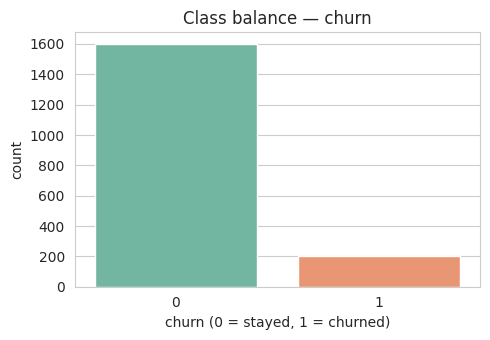

Minority class = 11.3% of data


In [11]:
# Class balance
TARGET = "churn"

print(df[TARGET].value_counts(dropna=False))
print("\nProportions:")
print(df[TARGET].value_counts(normalize=True, dropna=False).round(4))

plt.figure(figsize=(5, 3.5))
sns.countplot(x=df[TARGET], palette="Set2")
plt.title("Class balance — churn")
plt.xlabel("churn (0 = stayed, 1 = churned)")
plt.ylabel("count")
plt.tight_layout()
plt.show()

minority_pct = df[TARGET].value_counts(normalize=True).min() * 100
print(f"Minority class = {minority_pct:.1f}% of data")

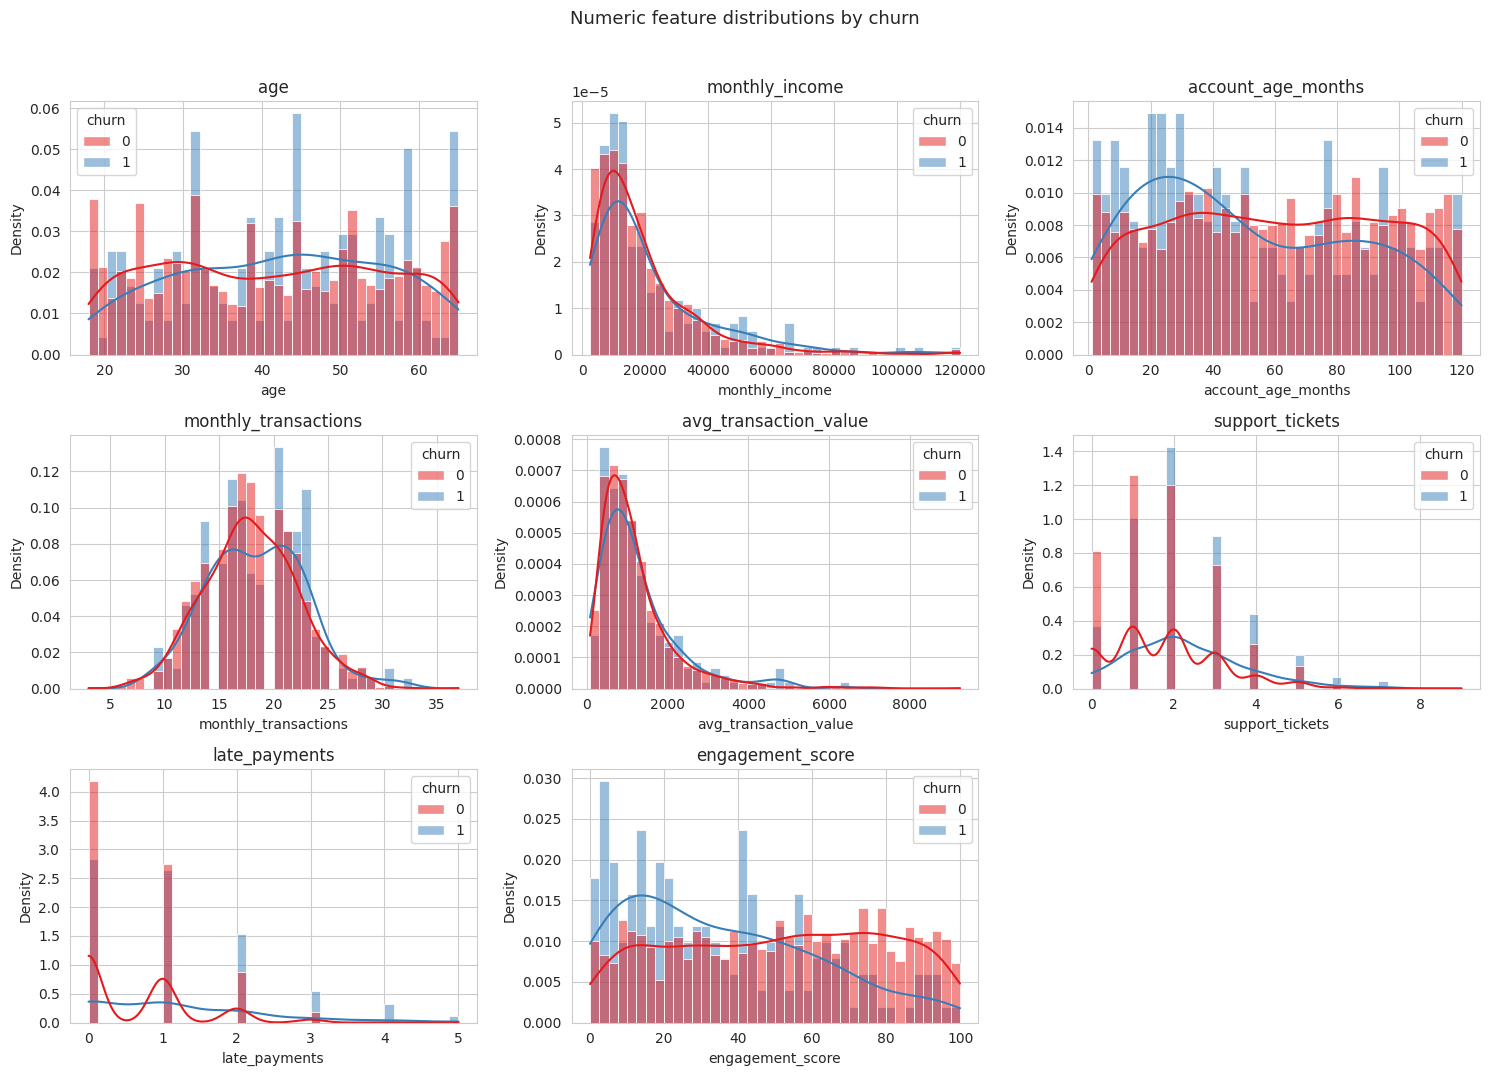

In [12]:
# Numeric feature distributions, colored by churn
num_cols = df.select_dtypes(include=[np.number]).columns.drop(TARGET).tolist()

ncols, nrows = 3, int(np.ceil(len(num_cols) / 3))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        data=df, x=col, hue=TARGET,
        bins=40, kde=True, stat="density", common_norm=False,
        ax=axes[i], palette="Set1", alpha=0.5,
    )
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Numeric feature distributions by churn", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

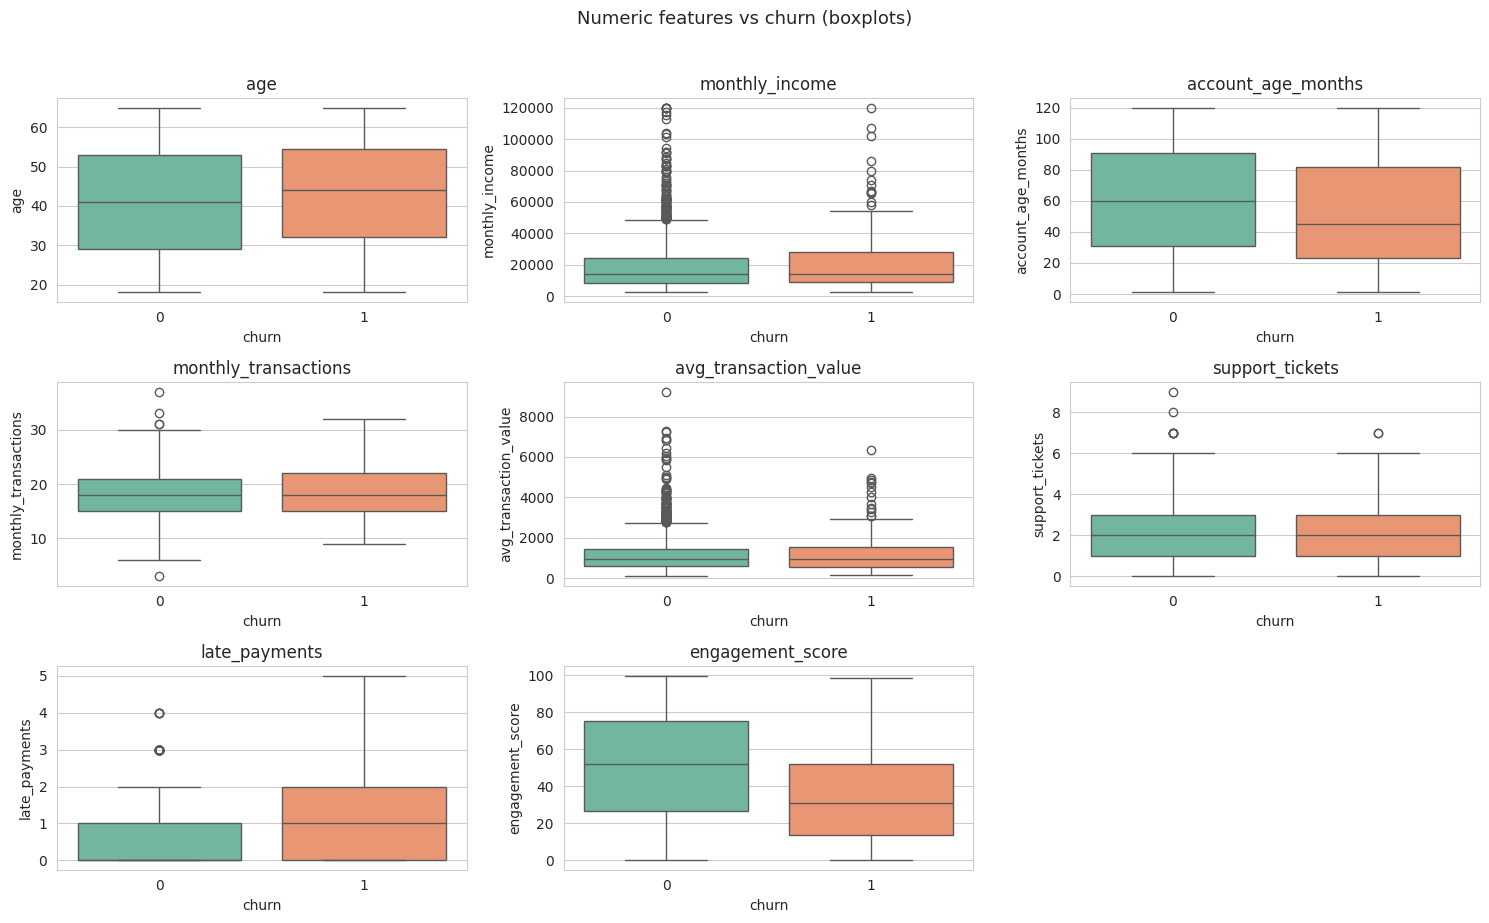

In [13]:
# Boxplots: numeric features vs churn
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[i], palette="Set2")
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Numeric features vs churn (boxplots)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

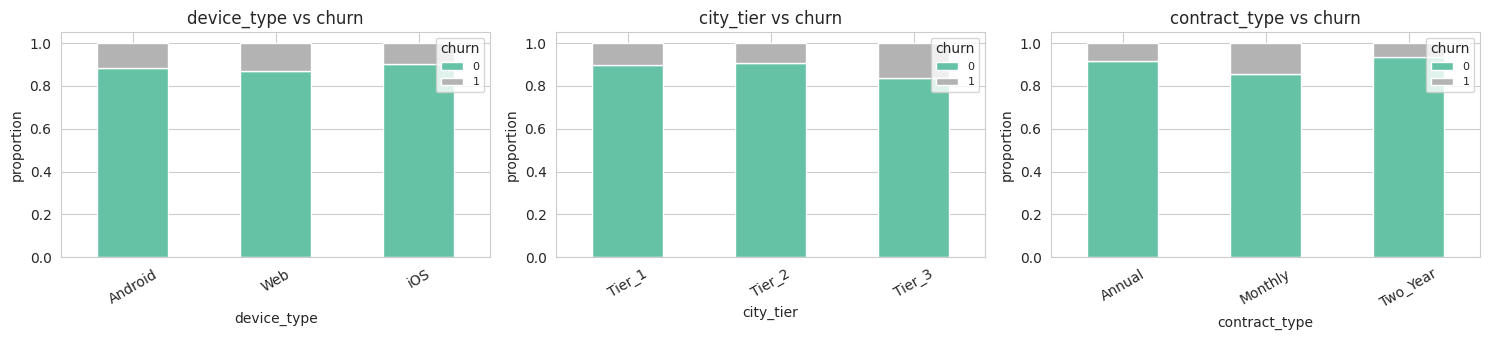

In [14]:
# Categorical features vs churn (stacked proportions)
fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 3.5))
if len(cat_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="Set2", edgecolor="white")
    ax.set_title(f"{col} vs churn")
    ax.set_ylabel("proportion")
    ax.set_xlabel(col)
    ax.legend(title="churn", loc="upper right", fontsize=8)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

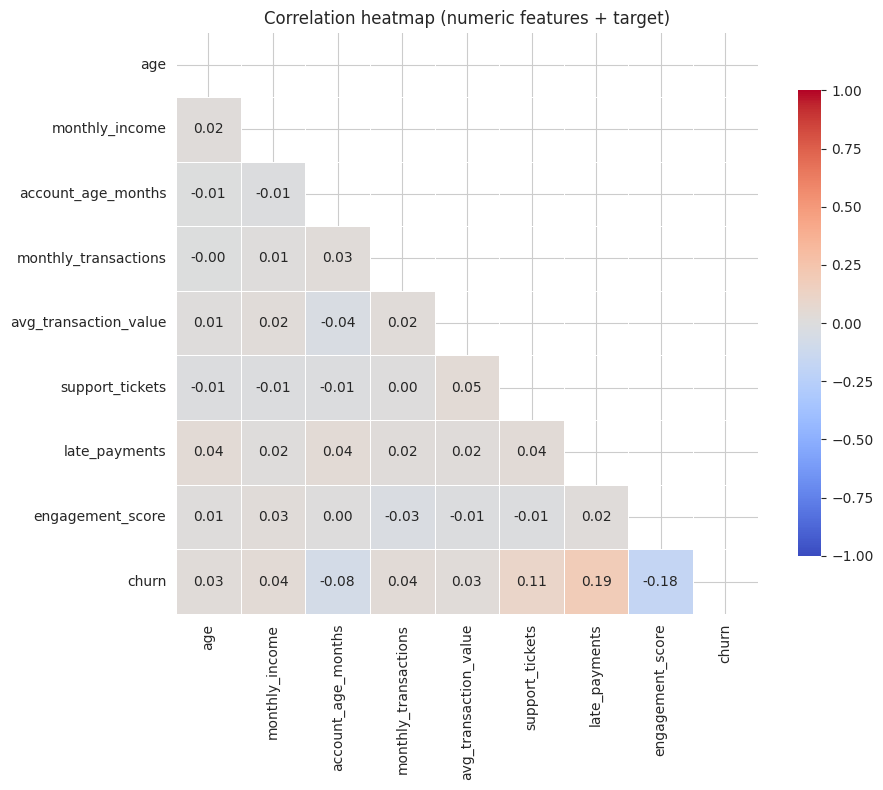

Features ranked by |correlation| with target:
late_payments            0.189
engagement_score        -0.176
support_tickets          0.109
account_age_months      -0.077
monthly_income           0.041
monthly_transactions     0.036
age                      0.028
avg_transaction_value    0.026
Name: churn, dtype: float64


In [15]:
# Correlation heatmap (numeric only)
corr = df[num_cols + [TARGET]].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
)
plt.title("Correlation heatmap (numeric features + target)")
plt.tight_layout()
plt.show()

target_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Features ranked by |correlation| with target:")
print(target_corr.round(3))

In [16]:
# Separate features (X) and target (y), then stratified split
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape:     {X_test.shape}")
print(f"\nTrain churn ratio: {y_train.mean():.3f}")
print(f"Test churn ratio:  {y_test.mean():.3f}")

Training set shape: (1440, 11)
Test set shape:     (360, 11)

Train churn ratio: 0.113
Test churn ratio:  0.114


### Data Preprocessing

In [17]:
# Build the preprocessing pipelines

# 1. Define feature groups based on EDA
skewed_cols = ["monthly_income", "avg_transaction_value"]
# Numeric columns that don't need log-transform (including late_payments)
normal_num_cols = [c for c in num_cols if c not in skewed_cols]
# Categorical columns (defined in EDA)
cat_cols = ["device_type", "city_tier", "contract_type"]

# 2. Skewed numeric columns: log1p -> standard scale
#    (log1p(x) = log(1 + x), which safely handles zero values)
skewed_pipeline = Pipeline([
    ("log_transform", FunctionTransformer(np.log1p, validate=False)),
    ("scaler", StandardScaler())
])

# 3. Other numeric columns: just scale
normal_num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

# 4. Categoricals: one-hot encode
cat_pipeline = Pipeline([
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

# 5. Combine into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("skewed", skewed_pipeline, skewed_cols),
        ("num", normal_num_pipeline, normal_num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(f"Original X_train shape: {X_train.shape}")
print(f"Preprocessed X_train shape: {X_train_prep.shape}")
print(f"Preprocessed X_test shape: {X_test_prep.shape}")

Original X_train shape: (1440, 11)
Preprocessed X_train shape: (1440, 14)
Preprocessed X_test shape: (360, 14)


### Evaluation Helpers

In [18]:
def evaluate_model(y_true, y_pred, y_proba, model_name="Model"):
    """Calculates key metrics and returns them as a dictionary."""
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Churn)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Churn)": recall_score(y_true, y_pred),
        "F1-Score (Churn)": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
    }


def report_model(y_true, y_proba, model_name, cmap="Blues", threshold=0.5):
    """Print the classification report + metrics, plot the confusion matrix, return the metrics dict."""
    y_pred = (y_proba > threshold).astype(int)
    results = evaluate_model(y_true, y_pred, y_proba, model_name)

    print("Classification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    print("Summary Metrics:")
    for k, v in results.items():
        if k != "Model":
            print(f"{k}: {v:.4f}")

    plt.figure(figsize=(4, 3))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap=cmap, cbar=False)
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return results

### Logistic Regression (No SMOTE)

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       319
           1       0.67      0.05      0.09        41

    accuracy                           0.89       360
   macro avg       0.78      0.52      0.52       360
weighted avg       0.87      0.89      0.84       360

Summary Metrics:
Accuracy: 0.8889
Precision (Churn): 0.6667
Recall (Churn): 0.0488
F1-Score (Churn): 0.0909
ROC-AUC: 0.7264
PR-AUC: 0.3522


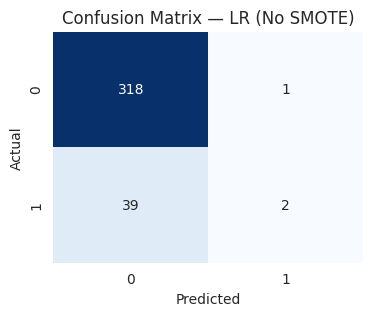

In [19]:
# Baseline: Logistic Regression (No SMOTE)
lr_baseline = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
lr_baseline.fit(X_train_prep, y_train)

y_proba_lr_base = lr_baseline.predict_proba(X_test_prep)[:, 1]
results_lr_base = report_model(y_test, y_proba_lr_base, "LR (No SMOTE)", cmap="Blues")

### Logistic Regression + SMOTE

Original train shape: (1440,), class balance: {0: 1278, 1: 162}
SMOTE'd train shape:  (2556,), class balance: {0: 1278, 1: 1278}

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.71      0.81       319
           1       0.21      0.61      0.32        41

    accuracy                           0.70       360
   macro avg       0.57      0.66      0.56       360
weighted avg       0.85      0.70      0.75       360

Summary Metrics:
Accuracy: 0.7000
Precision (Churn): 0.2137
Recall (Churn): 0.6098
F1-Score (Churn): 0.3165
ROC-AUC: 0.7316
PR-AUC: 0.3756


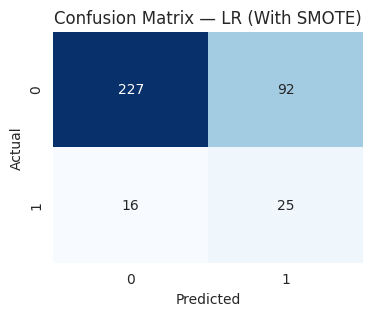

In [20]:
# Logistic Regression + SMOTE
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_prep, y_train)

print(f"Original train shape: {y_train.shape}, class balance: {pd.Series(y_train).value_counts().to_dict()}")
print(f"SMOTE'd train shape:  {y_train_sm.shape}, class balance: {pd.Series(y_train_sm).value_counts().to_dict()}\n")

lr_smote = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
lr_smote.fit(X_train_sm, y_train_sm)

y_proba_lr_smote = lr_smote.predict_proba(X_test_prep)[:, 1]
results_lr_smote = report_model(y_test, y_proba_lr_smote, "LR (With SMOTE)", cmap="Blues")

### Neural Network Setup

All four neural networks share the same architecture, optimizer and early-stopping rule, and each one is re-seeded right before training, so every model gives the same result no matter the order the cells are run in.

**Validation set:** 20% of the *real* training data is held out for early stopping **before** any resampling. SMOTE is applied only to the remaining 80%, so early stopping is never evaluated on synthetic samples. (Keras' `validation_split` simply takes the last 20% of the rows, and SMOTE appends all its synthetic rows at the end, so it would have validated on synthetic churners only.)

In [21]:
# Hold out real data for early stopping (stratified, so it keeps the ~11% churn rate)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_prep, y_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train
)
print(f"NN fit set:        {X_tr.shape}, churn ratio {y_tr.mean():.3f}")
print(f"NN validation set: {X_val.shape}, churn ratio {y_val.mean():.3f}")


def build_nn(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


def train_nn(X_fit, y_fit, class_weight=None):
    """Train one NN from a fixed seed so results are reproducible."""
    set_seeds()
    model = build_nn(X_fit.shape[1])
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )
    history = model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        class_weight=class_weight,
        callbacks=[early_stop],
        verbose=0
    )
    print(f"Stopped after {len(history.history['loss'])} epochs "
          f"(best val_loss: {min(history.history['val_loss']):.4f})")
    return model, history

NN fit set:        (1152, 14), churn ratio 0.113
NN validation set: (288, 14), churn ratio 0.111


### Neural Network (No SMOTE)

Training Neural Network (No SMOTE)...


E0000 00:00:1795470624.303392      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Stopped after 31 epochs (best val_loss: 0.3373)
Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       319
           1       0.00      0.00      0.00        41

    accuracy                           0.89       360
   macro avg       0.44      0.50      0.47       360
weighted avg       0.79      0.89      0.83       360

Summary Metrics:
Accuracy: 0.8861
Precision (Churn): 0.0000
Recall (Churn): 0.0000
F1-Score (Churn): 0.0000
ROC-AUC: 0.7652
PR-AUC: 0.3940


E0000 00:00:1795470630.602567      49 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


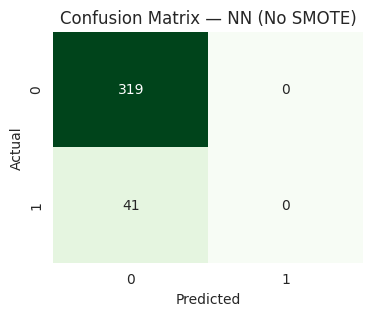

In [22]:
print("Training Neural Network (No SMOTE)...")
nn_base, history_base = train_nn(X_tr, y_tr)

y_proba_nn_base = nn_base.predict(X_test_prep, verbose=0).ravel()
results_nn_base = report_model(y_test, y_proba_nn_base, "NN (No SMOTE)", cmap="Greens")

### Neural Network + SMOTE

NN fit set after SMOTE: (2044, 14), class balance: {0: 1022, 1: 1022}

Training Neural Network (With SMOTE)...
Stopped after 37 epochs (best val_loss: 0.5006)
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.84      0.88       319
           1       0.26      0.44      0.32        41

    accuracy                           0.79       360
   macro avg       0.59      0.64      0.60       360
weighted avg       0.85      0.79      0.81       360

Summary Metrics:
Accuracy: 0.7917
Precision (Churn): 0.2571
Recall (Churn): 0.4390
F1-Score (Churn): 0.3243
ROC-AUC: 0.7085
PR-AUC: 0.2763


E0000 00:00:1795470640.237802      49 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


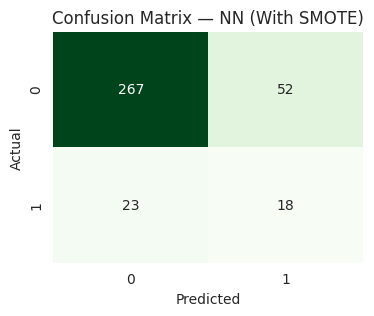

In [23]:
# SMOTE is applied to the NN fit set only (the validation set stays real)
X_tr_sm, y_tr_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)
print(f"NN fit set after SMOTE: {X_tr_sm.shape}, class balance: {pd.Series(y_tr_sm).value_counts().to_dict()}\n")

print("Training Neural Network (With SMOTE)...")
nn_smote, history_smote = train_nn(X_tr_sm, y_tr_sm)

y_proba_nn_smote = nn_smote.predict(X_test_prep, verbose=0).ravel()
results_nn_smote = report_model(y_test, y_proba_nn_smote, "NN (With SMOTE)", cmap="Greens")

### Neural Network with Class Weights (No SMOTE)

Calculated Class Weights: {0: np.float64(0.5636007827788649), 1: np.float64(4.430769230769231)}

Training Neural Network (Class Weights, No SMOTE)...
Stopped after 59 epochs (best val_loss: 0.5376)
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.76      0.83       319
           1       0.22      0.54      0.31        41

    accuracy                           0.73       360
   macro avg       0.57      0.65      0.57       360
weighted avg       0.85      0.73      0.78       360

Summary Metrics:
Accuracy: 0.7333
Precision (Churn): 0.2222
Recall (Churn): 0.5366
F1-Score (Churn): 0.3143
ROC-AUC: 0.7270
PR-AUC: 0.3254


E0000 00:00:1795470650.698371      49 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


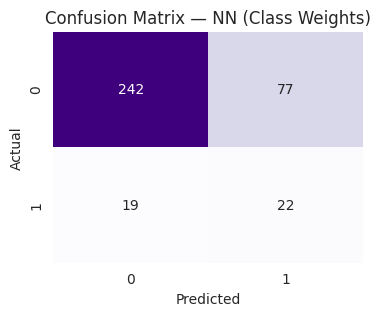

In [24]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_tr),
    y=y_tr
)
class_weights_dict = {i: weights[i] for i in range(len(weights))}
print(f"Calculated Class Weights: {class_weights_dict}\n")

print("Training Neural Network (Class Weights, No SMOTE)...")
nn_weighted, history_weighted = train_nn(X_tr, y_tr, class_weight=class_weights_dict)

y_proba_nn_weighted = nn_weighted.predict(X_test_prep, verbose=0).ravel()
results_nn_weighted = report_model(y_test, y_proba_nn_weighted, "NN (Class Weights)", cmap="Purples")

### Neural Network with Custom Class Weights

Applying custom weights: {0: 1.0, 1: 3.0}

Training Neural Network (Custom Class Weights)...
Stopped after 44 epochs (best val_loss: 0.3792)
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.95      0.93       319
           1       0.47      0.34      0.39        41

    accuracy                           0.88       360
   macro avg       0.69      0.65      0.66       360
weighted avg       0.87      0.88      0.87       360

Summary Metrics:
Accuracy: 0.8806
Precision (Churn): 0.4667
Recall (Churn): 0.3415
F1-Score (Churn): 0.3944
ROC-AUC: 0.7555
PR-AUC: 0.4167


E0000 00:00:1795470658.958457      49 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


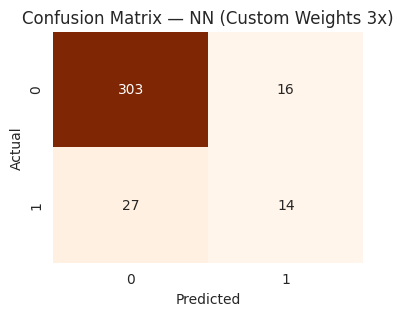

In [25]:
# Custom Class Weights (manual)
custom_weights = {
    0: 1.0,   # Normal penalty for missing a non-churner
    1: 3.0    # 3x penalty for missing a churner
}
print(f"Applying custom weights: {custom_weights}\n")

print("Training Neural Network (Custom Class Weights)...")
nn_custom, history_custom = train_nn(X_tr, y_tr, class_weight=custom_weights)

y_proba_nn_custom = nn_custom.predict(X_test_prep, verbose=0).ravel()
results_nn_custom = report_model(y_test, y_proba_nn_custom, "NN (Custom Weights 3x)", cmap="Oranges")

### Final Comparison

In [26]:
# Final Comparison Table
all_results = [
    results_lr_base,
    results_lr_smote,
    results_nn_base,
    results_nn_smote,
    results_nn_weighted,
    results_nn_custom
]

final_comparison_df = pd.DataFrame(all_results).set_index("Model").round(3)

styled_df = final_comparison_df.style.highlight_max(
    subset=["Recall (Churn)", "F1-Score (Churn)", "PR-AUC", "ROC-AUC"],
    color="Orange"
).highlight_max(
    subset=["Accuracy"],
    color="red"
)

display(styled_df)

,Accuracy,Precision (Churn),Recall (Churn),F1-Score (Churn),ROC-AUC,PR-AUC
Model,,,,,,
LR (No SMOTE),0.889000,0.667000,0.049000,0.091000,0.726000,0.352000
LR (With SMOTE),0.700000,0.214000,0.610000,0.316000,0.732000,0.376000
NN (No SMOTE),0.886000,0.000000,0.000000,0.000000,0.765000,0.394000
NN (With SMOTE),0.792000,0.257000,0.439000,0.324000,0.709000,0.276000
NN (Class Weights),0.733000,0.222000,0.537000,0.314000,0.727000,0.325000
NN (Custom Weights 3x),0.881000,0.467000,0.341000,0.394000,0.755000,0.417000


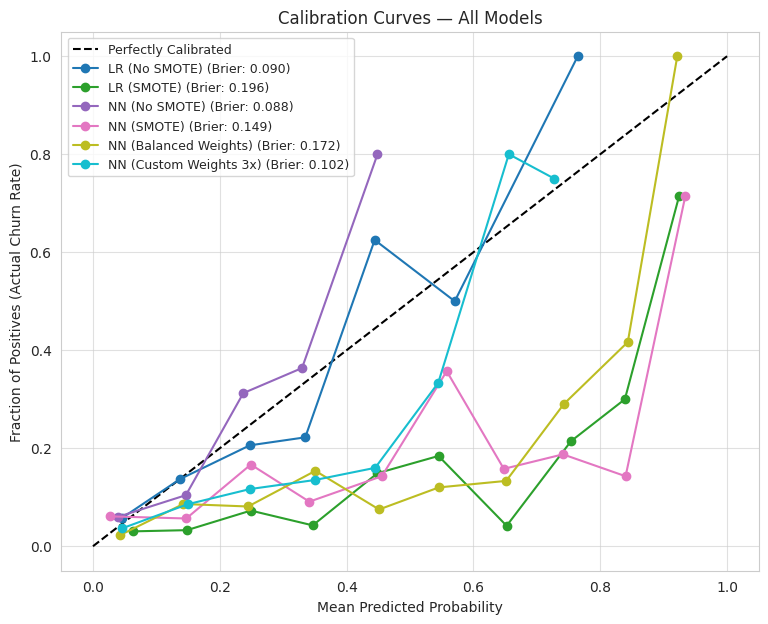

In [27]:
# Calibration Curves for All 6 Models
models = {
    "LR (No SMOTE)": y_proba_lr_base,
    "LR (SMOTE)": y_proba_lr_smote,
    "NN (No SMOTE)": y_proba_nn_base,
    "NN (SMOTE)": y_proba_nn_smote,
    "NN (Balanced Weights)": y_proba_nn_weighted,
    "NN (Custom Weights 3x)": y_proba_nn_custom
}

plt.figure(figsize=(9, 7))

plt.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfectly Calibrated", zorder=1)

colors = plt.cm.tab10(np.linspace(0, 1, len(models)))

for (name, proba), color in zip(models.items(), colors):
    prob_true, prob_pred = calibration_curve(y_test, proba, n_bins=10)
    brier = brier_score_loss(y_test, proba)
    plt.plot(prob_pred, prob_true, marker="o", color=color, label=f"{name} (Brier: {brier:.3f})")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives (Actual Churn Rate)")
plt.title("Calibration Curves — All Models")
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, alpha=0.6)
plt.show()

# Discussion & Conclusion

## 1. The Accuracy Mirage
Both baseline models look strong on accuracy (LR 88.9%, NN 88.6%), but 88.6% is exactly what a model gets by predicting "no churn" for all 360 customers (319 / 360). The baseline LR caught only 2 of the 41 churners (4.9% recall) and the baseline NN caught none. Accuracy is the wrong yardstick here; recall, precision, PR-AUC and the confusion matrices tell the real story.

## 2. What each approach actually buys you
Counts below are on the 360-customer test set (41 churners, 319 non-churners) at the default 0.5 threshold.

| Model | Churners caught (of 41) | False alarms (of 319) | Precision | F1 | ROC-AUC | PR-AUC | Brier |
|---|---|---|---|---|---|---|---|
| LR (No SMOTE) | 2 | 1 | 0.67 | 0.09 | 0.726 | 0.352 | 0.090 |
| LR + SMOTE | **25** | 92 | 0.21 | 0.32 | 0.732 | 0.376 | 0.196 |
| NN (No SMOTE) | 0 | 0 | n/a | 0.00 | **0.765** | 0.394 | **0.088** |
| NN + SMOTE | 18 | 52 | 0.26 | 0.32 | 0.709 | 0.276 | 0.149 |
| NN (Balanced weights) | 22 | 77 | 0.22 | 0.31 | 0.727 | 0.325 | 0.172 |
| NN (Custom weights 3x) | 14 | 16 | 0.47 | **0.39** | 0.755 | **0.417** | 0.102 |

- **Highest recall:** LR + SMOTE catches 61% of churners, but it flags about 117 customers to find those 25, so roughly 4 of every 5 retention offers go to someone who would have stayed.
- **Best balance:** NN with 3x custom weights has the best F1 and PR-AUC, and far higher precision (0.47) than the other models that catch a meaningful share of churners, at the cost of catching fewer of them (14 of 41). The baseline LR has a higher precision on paper, but it flags only 3 customers in total.
- **Weakest ranking quality:** NN + SMOTE has the lowest ROC-AUC and PR-AUC of all six models, even though its F1 is similar to the other resampling/weighting options.

Which one is "best" is a business decision: if a retention offer is cheap compared with the value of a lost customer, favour recall (LR + SMOTE); if offers are expensive or limited, favour precision (NN with 3x weights).

## 3. Mostly a threshold effect
Every model has a ROC-AUC between 0.71 and 0.77, so they rank customers in a broadly similar way. LR with and without SMOTE has almost the same ROC-AUC (0.726 vs 0.732) but a recall of 5% vs 61%. That suggests SMOTE and class weights mainly moved the decision threshold rather than teaching the model to separate churners better. The features are only weakly related to churn (the strongest correlation with the target is 0.19 for `late_payments`), which limits how well any model can do on this data.

## 4. The Calibration Trade-off
The two baselines have the best Brier scores (0.090 and 0.088), but for reference, always predicting the average churn rate (about 11%) would score roughly 0.100, so they are only slightly better than that. SMOTE (0.196 for LR, 0.149 for NN) and balanced class weights (0.172) push the predicted probabilities well above the true churn rate, so those probabilities should not be read as real churn risk. The 3x custom weights distort much less (0.102), though that is still no better than the constant baseline. If the business needs trustworthy probabilities, use an unadjusted model or recalibrate the adjusted one (e.g., Platt scaling or isotonic regression).

## 5. Limitations
- The test set contains only 41 churners, so one customer changes recall by about 2.4 percentage points. Small gaps between models (for example the 0.03 ROC-AUC difference between LR and the best NN) are not reliable evidence of a real difference.
- Results come from a single train/test split and a single seed per neural network.
- All models use a fixed 0.5 threshold; tuning the threshold on the precision-recall curve would likely change the ranking of the "balanced" options.
- The two SMOTE models are not trained on exactly the same data: LR + SMOTE oversamples the full training set, while NN + SMOTE oversamples only 80% of it (the other 20% is held out for early stopping), so the comparison between them is not perfectly like-for-like.

---

### Final Takeaway
Without any imbalance handling, both models look accurate but are useless for finding churners. SMOTE and class weights fix that by trading precision for recall, and how far to trade depends on the cost of a missed churner versus a wasted offer. On this small, weakly informative dataset, no model is clearly better than the others: the neural networks did not show a reliable advantage over logistic regression, and the simpler method of class weights worked as well as or better than SMOTE for the neural network. Repeated cross-validation and threshold tuning would be the next steps to turn these tendencies into firm conclusions.